# Cavity Resonance Frequency Analysis

This notebook uses a geometrical ray picture to estimate the resonance energy of the conical-hat mode in a hyperbolic hBN nanocavity. We then vary the cavity dimensions to show that the resonance is controlled by the aspect ratio.

## Setup

The next cell imports the numerical and plotting tools and loads the local permittivity model for isotopically pure $^{11}$ B hBN from the installed `methods` package. Energies are expressed in eV throughout the calculation.

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import fsolve
plt.style.use("https://johannesfeist.eu/misc/jf_cb.mplstyle")

import sys
sys.path.append('..')
from methods.hBN_permittivity import get_epsilon
eps_x, eps_z = get_epsilon(hbn_type="pure")

## Conical-hat mode

For the conical-hat trajectory, the geometrical resonance condition is

$$	\tan\theta(\omega) = \frac{R}{d},$$

where $d$ is the cavity width and $R$ is its radius. The propagation angle is determined by the anisotropic permittivity,

$$	\theta(\omega) = \frac{\pi}{2} - \arctan\sqrt{-\frac{\varepsilon_z(\omega)}{\varepsilon_x(\omega)}}.$$

The next cell defines the residual of this equation and a solver that returns the resonance energy $\hbar\omega_\mathrm{res}$.

In [13]:
def resonance_condition(energy_ev, d_nm, radius_nm):
    """Evaluate the conical-hat resonance condition."""
    anisotropy = np.sqrt(-eps_z(energy_ev) / eps_x(energy_ev))
    theta = np.pi / 2 - np.arctan(anisotropy)
    return np.real(np.tan(theta) - radius_nm / d_nm)


def find_w_res(d_nm, radius_nm, initial_guess_ev=0.18):
    """Find the conical-hat resonance energy in eV.

    Parameters
    ----------
    d_nm : float
        Cavity width in nanometres.
    radius_nm : float
        Cavity radius in nanometres.
    initial_guess_ev : float, optional
        Starting energy supplied to the nonlinear solver.

    Returns
    -------
    float
        Resonance energy in eV.
    """
    if d_nm <= 0 or radius_nm <= 0:
        raise ValueError("Cavity dimensions must be positive.")

    solution, _, converged, message = fsolve(
        resonance_condition,
        x0=initial_guess_ev,
        args=(d_nm, radius_nm),
        full_output=True,
    )
    if converged != 1:
        raise RuntimeError(f"Could not find the resonance: {message}")

    return float(solution[0])

### Example cavity

We first evaluate a cavity with $d=25$ nm and $R=40$ nm. The calculated resonance is reported both as an energy and as an ordinary frequency.

In [14]:
d_nm = 25
radius_nm = 40

w_res_ev = find_w_res(d_nm, radius_nm)
f_res_thz = w_res_ev * 241.79893

print(f"Resonance energy: {w_res_ev:.6f} eV")
print(f"Resonance frequency: {f_res_thz:.3f} THz")

Resonance energy: 0.181942 eV
Resonance frequency: 43.993 THz


### Dependence on cavity dimensions

Next, we solve the resonance condition over a grid of widths and radii. This produces a two-dimensional map that can be compared with contours of constant aspect ratio $d/R$.

In [15]:
d_values_nm = np.linspace(25, 40, 35)
radius_values_nm = np.linspace(20, 80, 30)

w_res_grid_ev = np.array([
    [find_w_res(d_nm, radius_nm) for radius_nm in radius_values_nm]
    for d_nm in d_values_nm
])

The colour map below shows the resonance energy. Dashed lines mark constant aspect ratio $d/R$; their alignment with the colour bands makes the aspect-ratio dependence visible.

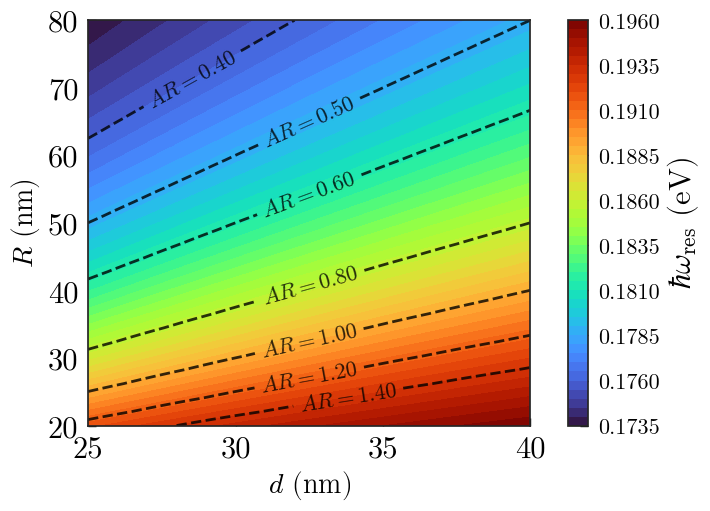

In [16]:
radius_grid_nm, d_grid_nm = np.meshgrid(radius_values_nm, d_values_nm)
aspect_ratio_grid = d_grid_nm / radius_grid_nm

fig, ax = plt.subplots(figsize=(7, 5))
resonance_map = ax.contourf(d_grid_nm, radius_grid_nm, w_res_grid_ev, levels=50)
colorbar = fig.colorbar(resonance_map, ax=ax)
colorbar.set_label(r"$\hbar\omega_\mathrm{res}$ (eV)", fontsize=22)

ratio_levels = [0.4, 0.5, 0.6, 0.8, 1.0, 1.2, 1.4]
ratio_contours = ax.contour(
    d_grid_nm,
    radius_grid_nm,
    aspect_ratio_grid,
    levels=ratio_levels,
    colors="black",
    linestyles="dashed",
    alpha=0.8,
)
ax.clabel(ratio_contours, inline=True, fmt=r"$AR=%.2f$")
ax.set_xlabel(r"$d$ (nm)", fontsize=20)
ax.set_ylabel(r"$R$ (nm)", fontsize=20);
ax.tick_params(axis="both", which="major", labelsize=22)

### Aspect-ratio scaling

To test the scaling directly, we generate two parameter sweeps. In the first, $R$ is fixed while $d$ varies; in the second, $d$ is fixed while $R$ varies. Plotting both results against $d/R$ should collapse them onto the same curve if the resonance depends only on the aspect ratio.

In [17]:
fixed_radius_nm = 30
varying_d_nm = np.linspace(20, 40, 30)
w_res_fixed_radius_ev = np.array([
    find_w_res(d_nm, fixed_radius_nm) for d_nm in varying_d_nm
])

fixed_d_nm = 35
varying_radius_nm = np.linspace(20, 100, 30)
w_res_fixed_d_ev = np.array([
    find_w_res(fixed_d_nm, radius_nm) for radius_nm in varying_radius_nm
])

The final cell overlays the two sweeps. Their collapse confirms that, within this geometrical model, cavities with the same $d/R$ have the same conical-hat resonance energy.

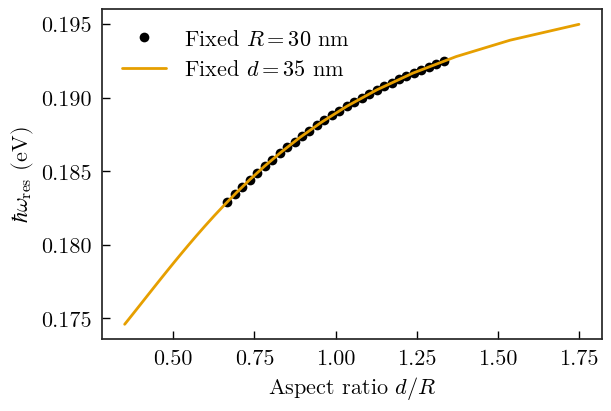

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(
    varying_d_nm / fixed_radius_nm,
    w_res_fixed_radius_ev,
    "o",
    label=fr"Fixed $R={fixed_radius_nm}$ nm",
)
ax.plot(
    fixed_d_nm / varying_radius_nm,
    w_res_fixed_d_ev,
    "-",
    label=fr"Fixed $d={fixed_d_nm}$ nm",
)
ax.set(xlabel=r"Aspect ratio $d/R$", ylabel=r"$\hbar\omega_\mathrm{res}$ (eV)")
ax.legend();